In [1]:
from pathlib import Path
from IPython.display import display
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = None  # e.g. '/content/bank-additional-full.csv'
candidates = [Path(DATA_PATH)] if DATA_PATH else [Path('bank-additional-full.csv'), Path('../bank-additional-full.csv'), Path('data/bank-additional-full.csv'), Path('/content/bank-additional-full.csv')]
data_file = next((p for p in candidates if p.is_file()), None)
if data_file is None:
    raise FileNotFoundError('Upload bank-additional-full.csv or set DATA_PATH to its location, then Run All.')
raw_df = pd.read_csv(data_file, sep=';')
print('Loaded:', data_file.resolve())


Loaded: /content/bank-additional-full.csv


# Bank Marketing EDA

This notebook reviews the bank marketing dataset, summarizes the available features, and looks for patterns that relate to subscription outcomes.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = raw_df.copy()

# data size
print("Rows and columns:", df.shape)
display(df.head())

# data type & non-empty
df.info()

Rows and columns: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    recall_score,
)

bank = df.copy()
bank = bank.drop(columns=["duration"], errors="ignore")


In [4]:
print("\nNumerical summary:\n")
print(bank.describe(include=[np.number]).T)
print("\nCategorical summary:\n")
print(bank.describe(include=["object", "category"]).T)
print("\nColumns:\n", bank.columns.tolist())



Numerical summary:

                  count         mean         std       min       25%  \
age             41188.0    40.024060   10.421250    17.000    32.000   
campaign        41188.0     2.567593    2.770014     1.000     1.000   
pdays           41188.0   962.475454  186.910907     0.000   999.000   
previous        41188.0     0.172963    0.494901     0.000     0.000   
emp.var.rate    41188.0     0.081886    1.570960    -3.400    -1.800   
cons.price.idx  41188.0    93.575664    0.578840    92.201    93.075   
cons.conf.idx   41188.0   -40.502600    4.628198   -50.800   -42.700   
euribor3m       41188.0     3.621291    1.734447     0.634     1.344   
nr.employed     41188.0  5167.035911   72.251528  4963.600  5099.100   

                     50%       75%       max  
age               38.000    47.000    98.000  
campaign           2.000     3.000    56.000  
pdays            999.000   999.000   999.000  
previous           0.000     0.000     7.000  
emp.var.rate       1.10

In [5]:
# Check for null values and unknown values encoded as strings
quality_check = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "unknown_count": df.eq("unknown").sum()
})

quality_check["unknown_percent"] = (
    quality_check["unknown_count"] / len(df) * 100
).round(2)

display(quality_check)

# check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

,missing_count,unknown_count,unknown_percent
age,0,0,0.00
job,0,330,0.80
marital,0,80,0.19
education,0,1731,4.20
default,0,8597,20.87
housing,0,990,2.40
loan,0,990,2.40
contact,0,0,0.00
month,0,0,0.00
day_of_week,0,0,0.00


Duplicate rows: 12


### Data Quality Summary

No null values were detected in any column. However, six categorical
columns contain `unknown` values, indicating unavailable information.

The highest unknown rate is in `default` (20.87%), followed by
`education` (4.20%).

There are 12 exact duplicate rows.

,age
count,41188.00000
mean,40.02406
std,10.42125
min,17.00000
25%,32.00000
50%,38.00000
75%,47.00000
max,98.00000


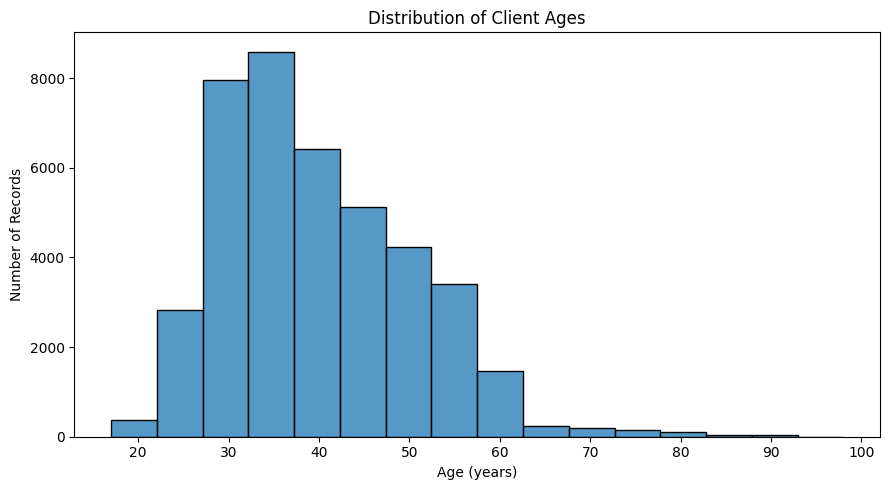

In [6]:
# Summarize client ages
display(df["age"].describe())

# Plot the distribution of client ages
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="age", binwidth=5)

plt.title("Distribution of Client Ages")
plt.xlabel("Age (years)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

### Client Age Summary

Client ages range from 17 to 98 years. The mean age is approximately
40.02 years, and the median is 38 years. The middle 50% of ages fall
between 32 and 47 years. The standard deviation is approximately
10.42 years.

,count,percent
job,,
admin.,10422,25.30
blue-collar,9254,22.47
technician,6743,16.37
services,3969,9.64
management,2924,7.10
retired,1720,4.18
entrepreneur,1456,3.54
self-employed,1421,3.45
housemaid,1060,2.57


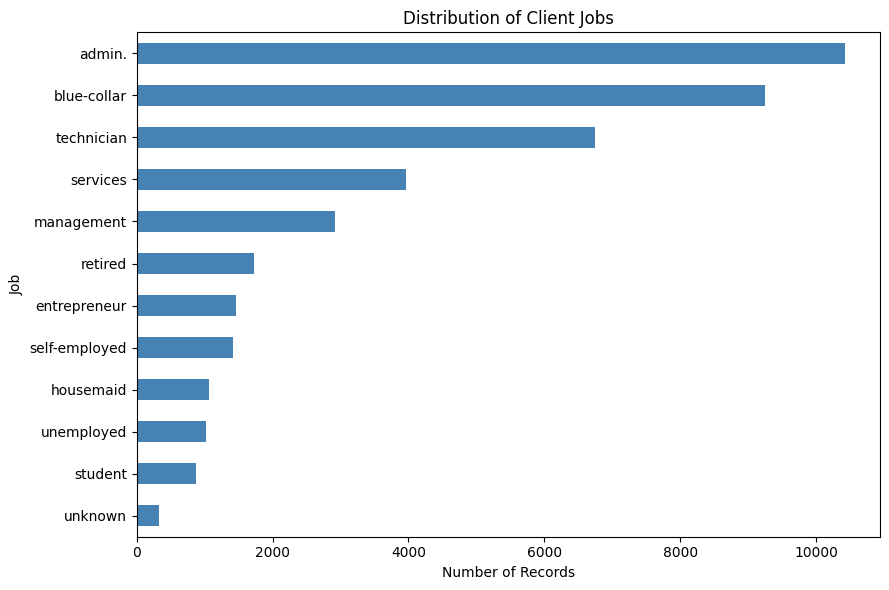

In [7]:
# Explore the distribution of client jobs
job_summary = df["job"].value_counts().to_frame("count")

job_summary["percent"] = (
    job_summary["count"] / len(df) * 100
).round(2)

display(job_summary)

# Plot the number of records by job
ax = job_summary["count"].sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    color="steelblue"
)

ax.set_title("Distribution of Client Jobs")
ax.set_xlabel("Number of Records")
ax.set_ylabel("Job")

plt.tight_layout()
plt.show()

### Client Job Distribution

The most common job categories are administrative workers (25.30%),
blue-collar workers (22.47%), and technicians (16.37%). Together, they
account for approximately 64.14% of all records.

Students are the least represented known job category (2.12%).
Job information is unknown for 0.80% of records.

In [8]:
# Check the distribution of default status
default_summary = df["default"].value_counts().to_frame("count")
default_summary["percent"] = (
    default_summary["count"] / len(df) * 100
).round(2)

display(default_summary)

,count,percent
default,,
no,32588,79.12
unknown,8597,20.87
yes,3,0.01


In [9]:
# Check the distribution of housing loan status
housing_summary = df["housing"].value_counts().to_frame("count")
housing_summary["percent"] = (
    housing_summary["count"] / len(df) * 100
).round(2)

display(housing_summary)

,count,percent
housing,,
yes,21576,52.38
no,18622,45.21
unknown,990,2.40


In [10]:
# Check the distribution of loan status
loan_summary = df["loan"].value_counts().to_frame("count")
loan_summary["percent"] = (
    loan_summary["count"] / len(df) * 100
).round(2)

display(loan_summary)

,count,percent
loan,,
no,33950,82.43
yes,6248,15.17
unknown,990,2.40


In [11]:
# Check the distribution of y status
y_summary = df["y"].value_counts().to_frame("count")
y_summary["percent"] = (
    y_summary["count"] / len(df) * 100
).round(2)

display(y_summary)

,count,percent
y,,
no,36548,88.73
yes,4640,11.27


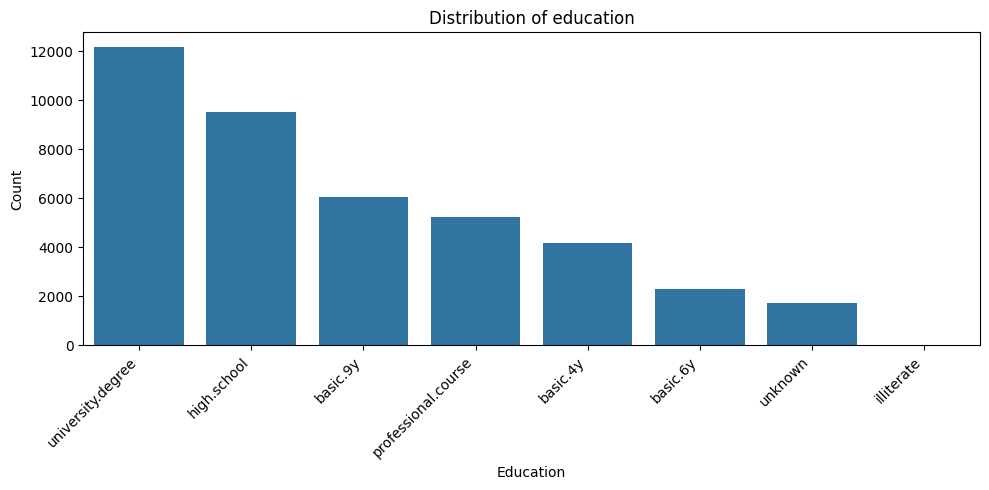


education counts:
education
university.degree      12168
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
unknown                 1731
illiterate                18
Name: count, dtype: int64


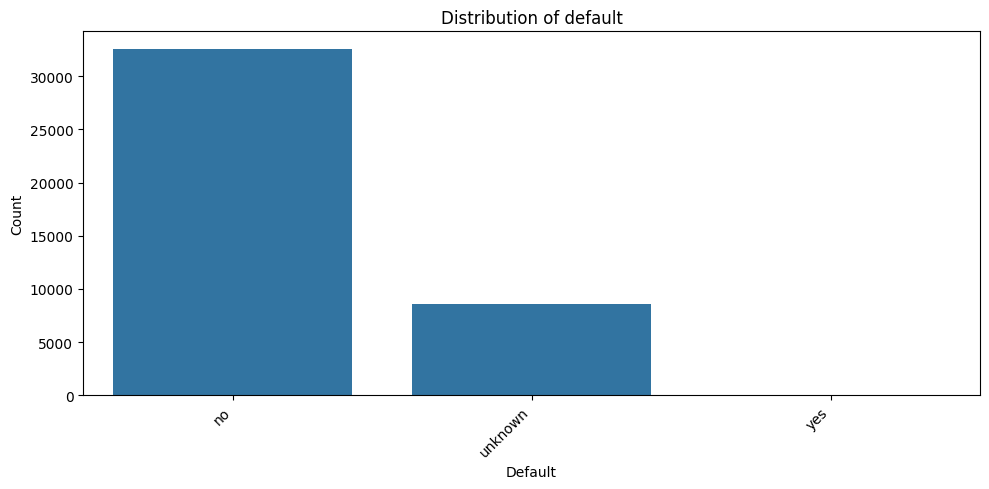

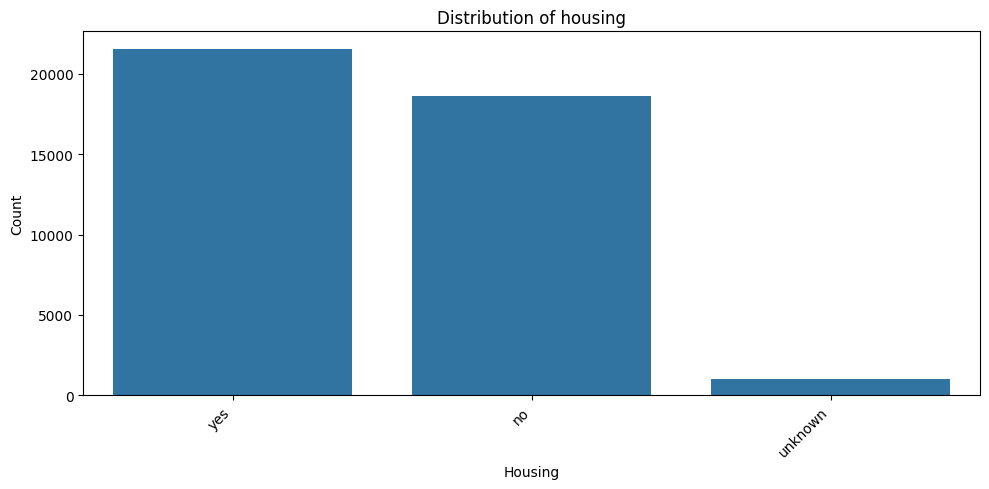

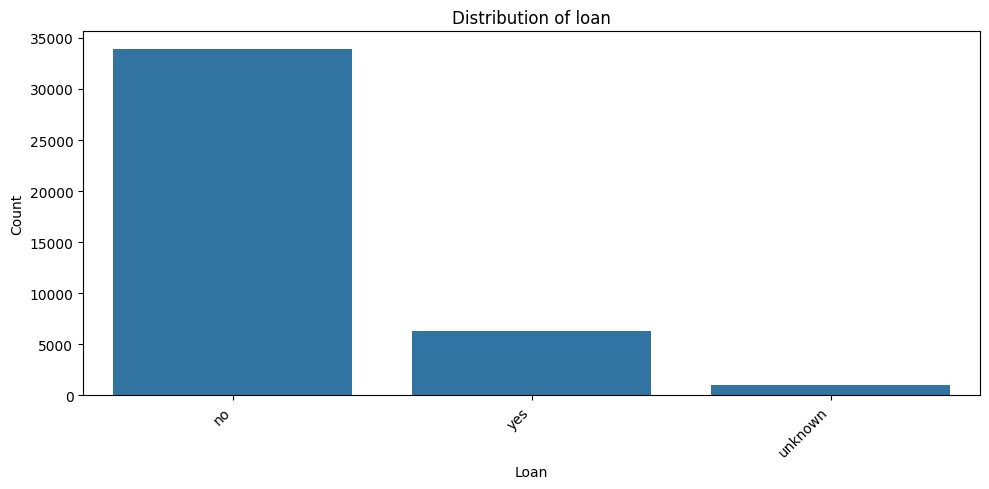

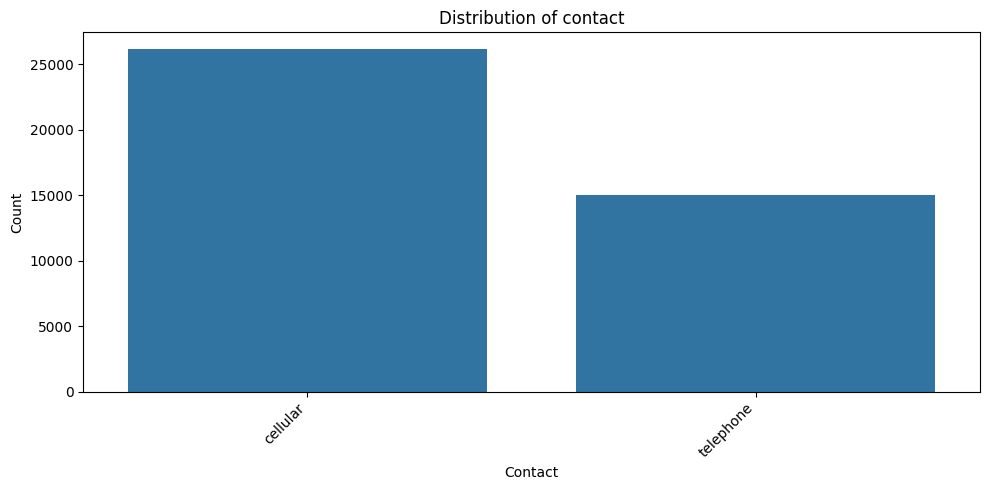


contact counts:
contact
cellular     26144
telephone    15044
Name: count, dtype: int64


In [12]:
for col in ["education", "default", "housing", "loan", "contact"]:
    counts = bank[col].value_counts()
    plt.figure(figsize=(10, 5))
    sns.barplot(x=counts.index.astype(str), y=counts.values)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
    if col in ["education", "contact"]:
        print(f"\n{col} counts:\n{counts}")


In [13]:
# Summarize the number of contacts per client
display(df["campaign"].describe())

# Count records for each number of contacts
campaign_summary = (
    df["campaign"]
    .value_counts()
    .head(5)
    .to_frame("count")
)

campaign_summary["percent"] = (
    campaign_summary["count"] / len(df) * 100
).round(2)

display(campaign_summary)

,campaign
count,41188.000000
mean,2.567593
std,2.770014
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,56.000000


,count,percent
campaign,,
1,17642,42.83
2,10570,25.66
3,5341,12.97
4,2651,6.44
5,1599,3.88


### Campaign Distribution

Most records have a small number of contacts during the current campaign.
One contact is the most common (42.83%), and approximately 81.46% of
records have 1–3 contacts. The mean is 2.57 contacts, while the median
is 2. The maximum is 56, indicating a right-skewed distribution with
a small number of high contact counts.

,count,percent
poutcome,,
nonexistent,35563,86.34
failure,4252,10.32
success,1373,3.33


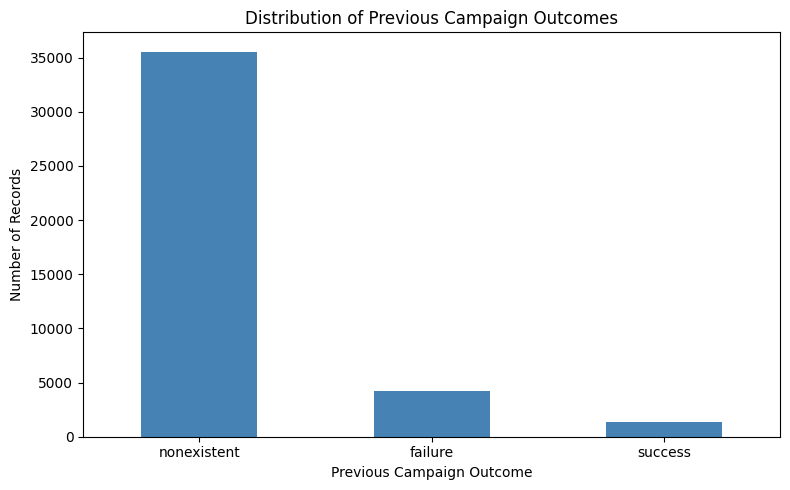

In [14]:
# Explore previous campaign outcomes
poutcome_summary = df["poutcome"].value_counts().to_frame("count")

poutcome_summary["percent"] = (
    poutcome_summary["count"] / len(df) * 100
).round(2)

display(poutcome_summary)

ax = poutcome_summary["count"].plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue",
    rot=0
)

ax.set_title("Distribution of Previous Campaign Outcomes")
ax.set_xlabel("Previous Campaign Outcome")
ax.set_ylabel("Number of Records")

plt.tight_layout()
plt.show()

### Previous Campaign Outcome Distribution

Most records have no previous campaign outcome (`nonexistent`, 86.34%).
Previous campaigns were recorded as failures for 10.32% of records
and successes for 3.33%.

In [15]:
# Check whether clients were previously contacted
previously_contacted = df["pdays"].ne(999)

pdays_summary = (
    previously_contacted.value_counts()
    .rename(index={True: "Previously contacted",
                   False: "Maybe not previously contacted"})
    .to_frame("count")
)

pdays_summary["percent"] = (
    pdays_summary["count"] / len(df) * 100
).round(2)

display(pdays_summary)

# Summarize actual intervals for previously contacted records
display(df.loc[previously_contacted, "pdays"].describe())

,count,percent
pdays,,
Maybe not previously contacted,39673,96.32
Previously contacted,1515,3.68


,pdays
count,1515.000000
mean,6.014521
std,3.824906
min,0.000000
25%,3.000000
50%,6.000000
75%,7.000000
max,27.000000


### Days Since Previous Contact

The special value 999 appears in 96.32% of `pdays` records and is
excluded from the numerical summary of contact intervals.

For the remaining 1,515 records (3.68%), the intervals range from
0 to 27 days. The mean is 6.01 days, and the median is 6 days.
The middle 50% of intervals fall between 3 and 7 days.

## Conversion and campaign outcomes

This block focuses on response rates and how variables like age, campaign recency, and category segments are associated with subscription success.


Overall subscription rate: 11.27%

Subscription rate by job:
          job  total  subscribers  subscription_rate
      student    875          275           0.314286
      retired   1720          434           0.252326
   unemployed   1014          144           0.142012
       admin.  10422         1352           0.129726
   management   2924          328           0.112175
      unknown    330           37           0.112121
   technician   6743          730           0.108260
self-employed   1421          149           0.104856
    housemaid   1060          106           0.100000
 entrepreneur   1456          124           0.085165
     services   3969          323           0.081381
  blue-collar   9254          638           0.068943


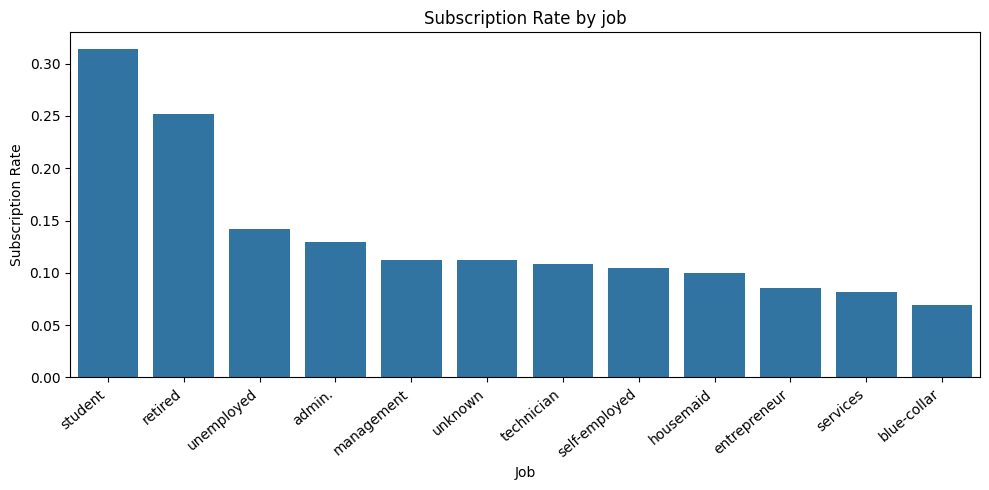


Subscription rate by education:
          education  total  subscribers  subscription_rate
         illiterate     18            4           0.222222
            unknown   1731          251           0.145003
  university.degree  12168         1670           0.137245
professional.course   5243          595           0.113485
        high.school   9515         1031           0.108355
           basic.4y   4176          428           0.102490
           basic.6y   2292          188           0.082024
           basic.9y   6045          473           0.078246


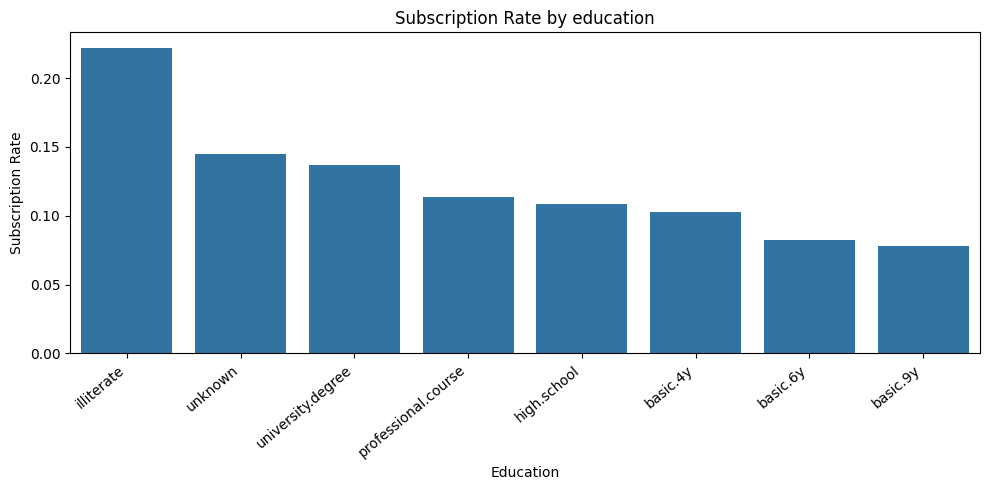


Subscription rate by marital:
 marital  total  subscribers  subscription_rate
 unknown     80           12           0.150000
  single  11568         1620           0.140041
divorced   4612          476           0.103209
 married  24928         2532           0.101573


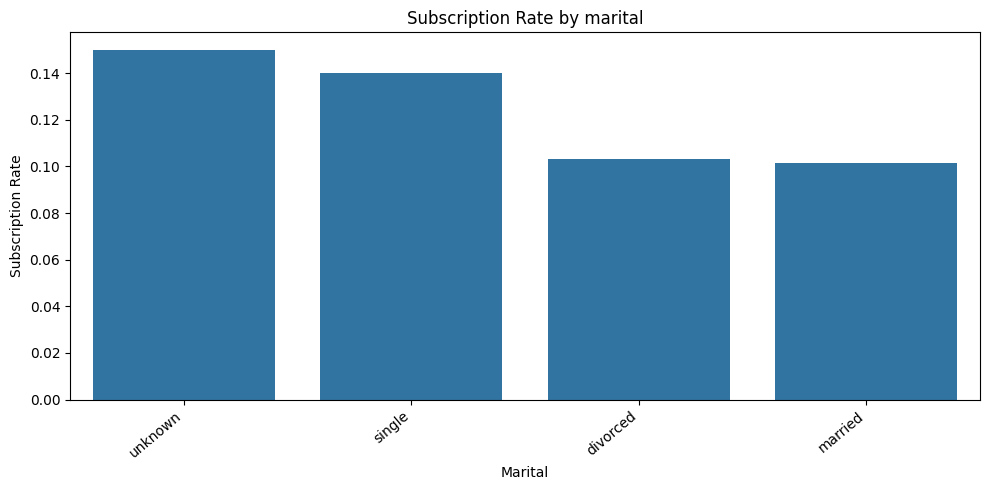


Subscription rate by housing:
housing  total  subscribers  subscription_rate
    yes  21576         2507           0.116194
     no  18622         2026           0.108796
unknown    990          107           0.108081


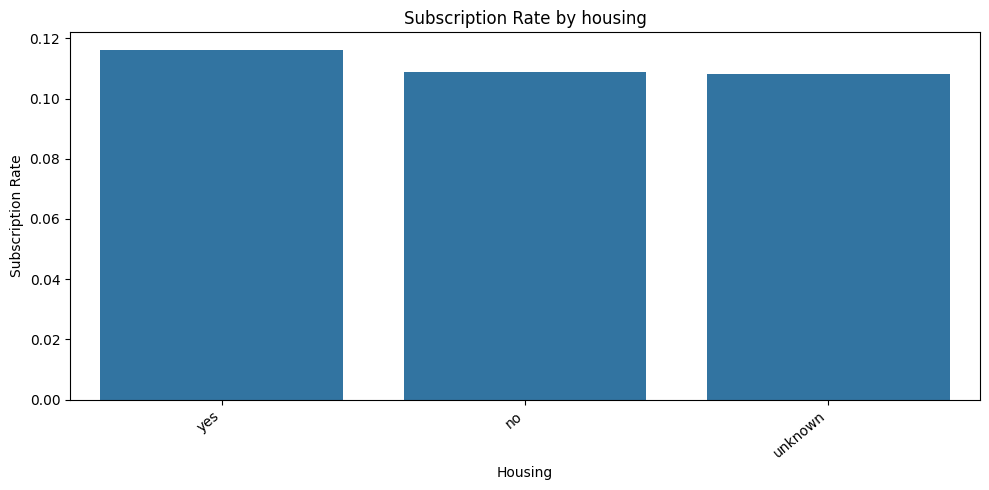


Subscription rate by loan:
   loan  total  subscribers  subscription_rate
     no  33950         3850           0.113402
    yes   6248          683           0.109315
unknown    990          107           0.108081


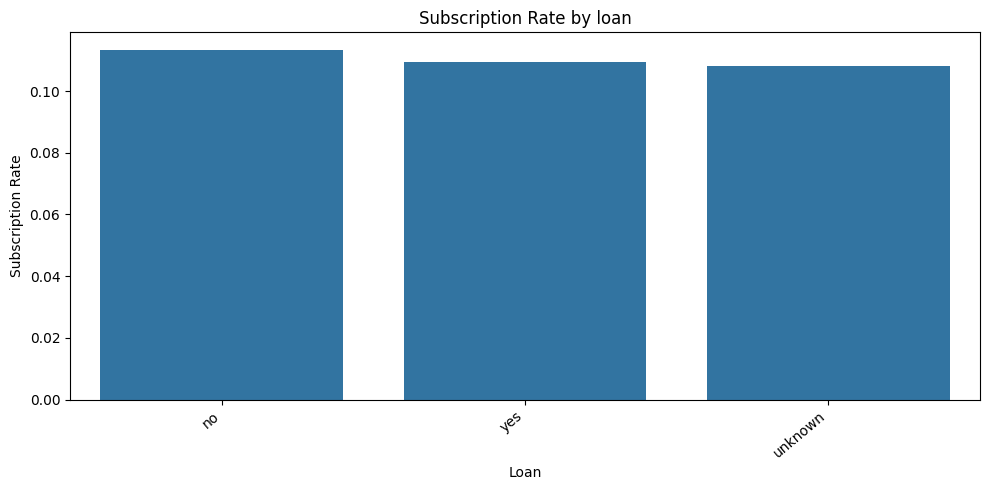


Subscription rate by default:
default  total  subscribers  subscription_rate
     no  32588         4197            0.12879
unknown   8597          443            0.05153
    yes      3            0            0.00000


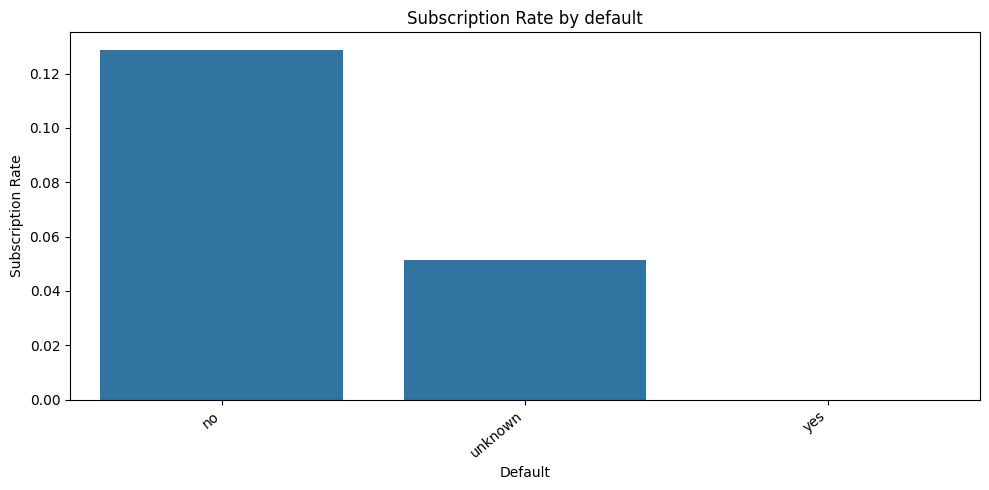

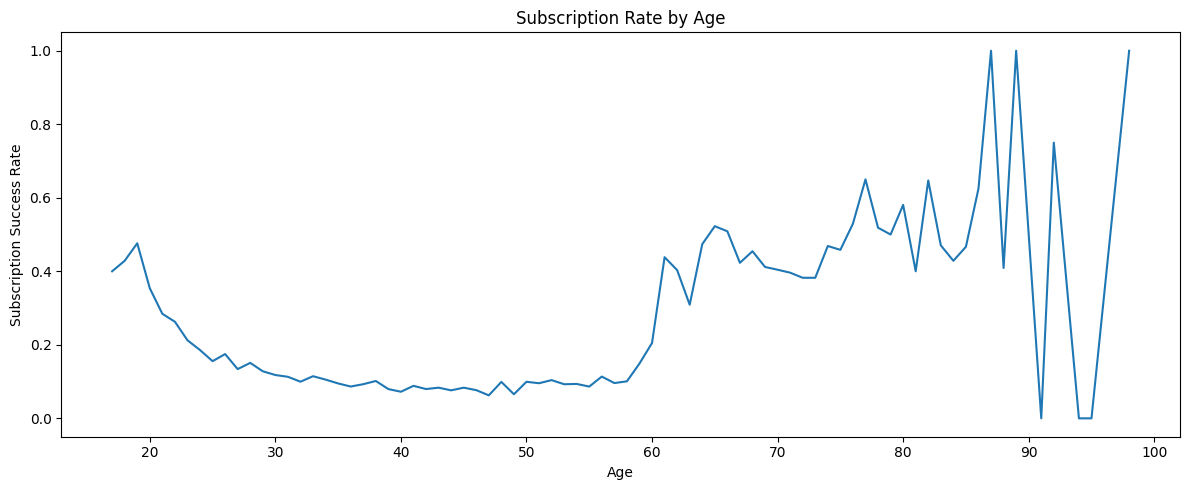

In [16]:
success_rate = (bank["y"] == "yes").mean()
print(f"Overall subscription rate: {success_rate:.2%}")

for col in ["job", "education", "marital", "housing", "loan", "default"]:
    summary = (
        bank.groupby(col, observed=True)["y"]
        .agg(total="count", subscribers=lambda s: (s == "yes").sum())
        .reset_index()
    )
    summary["subscription_rate"] = summary["subscribers"] / summary["total"]
    summary = summary.sort_values("subscription_rate", ascending=False)
    print(f"\nSubscription rate by {col}:")
    print(summary.to_string(index=False))

    plt.figure(figsize=(10, 5))
    sns.barplot(data=summary, x=col, y="subscription_rate")
    plt.title(f"Subscription Rate by {col}")
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel("Subscription Rate")
    plt.xticks(rotation=40, ha="right")
    plt.tight_layout()
    plt.show()

age_success = bank.groupby("age")["y"].apply(lambda s: (s == "yes").mean())
plt.figure(figsize=(12, 5))
sns.lineplot(x=age_success.index, y=age_success.values)
plt.xlabel("Age")
plt.ylabel("Subscription Success Rate")
plt.title("Subscription Rate by Age")
plt.tight_layout()
plt.show()



Success rate by previous contact timing:
                          success_rate  count
pdays_bucket                                 
0 days                        0.666667     15
1-5 days                      0.630435    690
6-10 days                     0.669967    606
11-20 days                    0.556122    196
21-50 days                    0.875000      8
51-100 days                        NaN      0
101-500 days                       NaN      0
501-998 days                       NaN      0
Not previously contacted      0.092582  39673


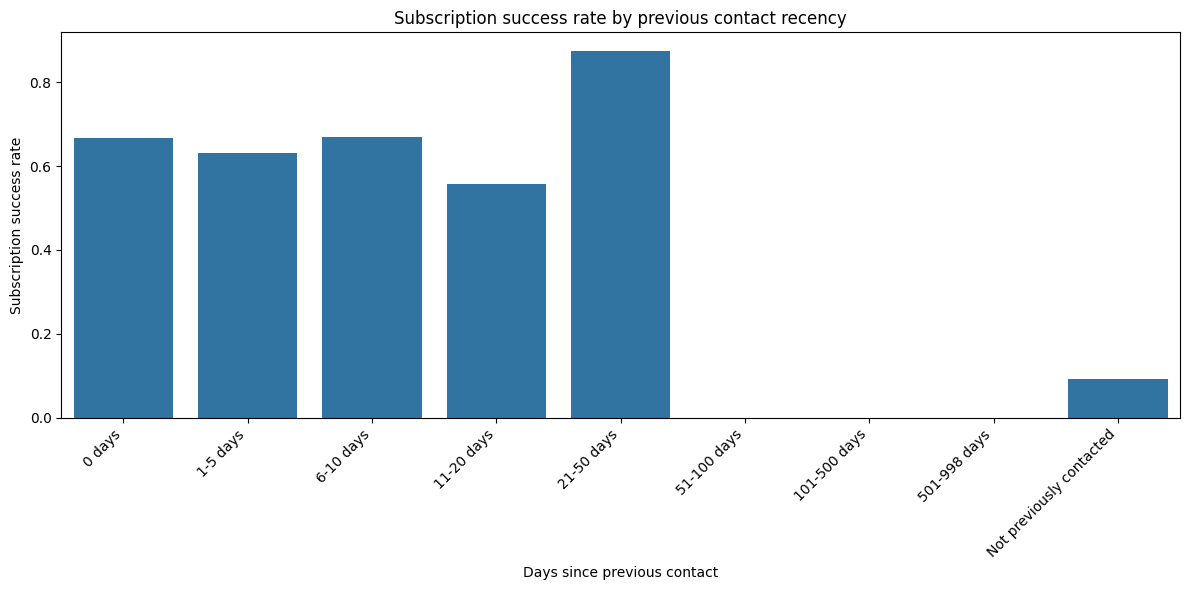

In [17]:
# Previous contact analysis
bank["success"] = (bank["y"] == "yes").astype(int)

pdays = bank["pdays"].copy()
bins = [-1, 0, 5, 10, 20, 50, 100, 500, 998, 999]
labels = [
    "0 days",
    "1-5 days",
    "6-10 days",
    "11-20 days",
    "21-50 days",
    "51-100 days",
    "101-500 days",
    "501-998 days",
    "Not previously contacted",
]

pdays_summary = (
    bank.assign(pdays_bucket=pd.cut(pdays, bins=bins, labels=labels, include_lowest=True))
    .groupby("pdays_bucket", observed=False)
    .agg(success_rate=("success", "mean"), count=("success", "size"))
)
print("\nSuccess rate by previous contact timing:")
print(pdays_summary)

plt.figure(figsize=(12, 6))
sns.barplot(x=pdays_summary.index.astype(str), y=pdays_summary["success_rate"])
plt.xlabel("Days since previous contact")
plt.ylabel("Subscription success rate")
plt.title("Subscription success rate by previous contact recency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


,count,subscribers,percent,subscription_rate
marital,,,,
married,24928,2532,60.522482,0.101573
single,11568,1620,28.085850,0.140041
divorced,4612,476,11.197436,0.103209
unknown,80,12,0.194231,0.150000


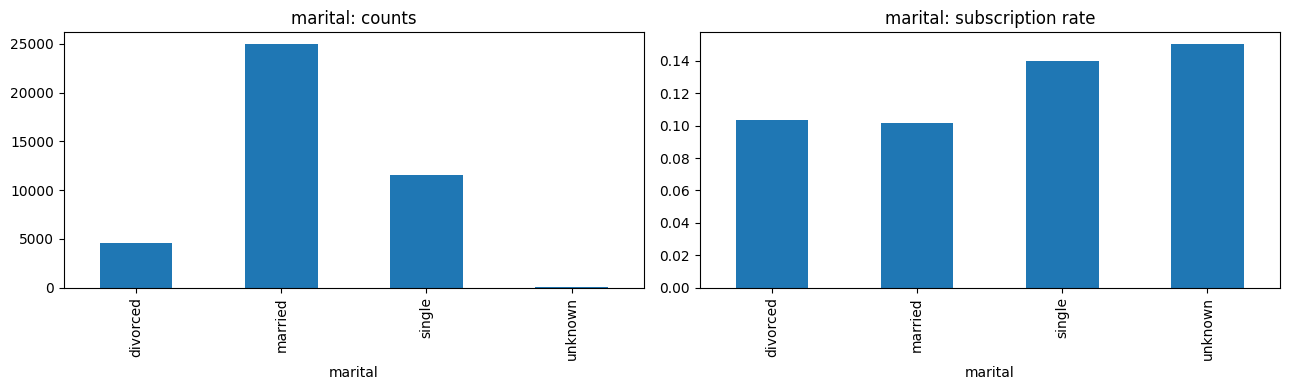

,count,subscribers,percent,subscription_rate
contact,,,,
cellular,26144,3853,63.474798,0.147376
telephone,15044,787,36.525202,0.052313


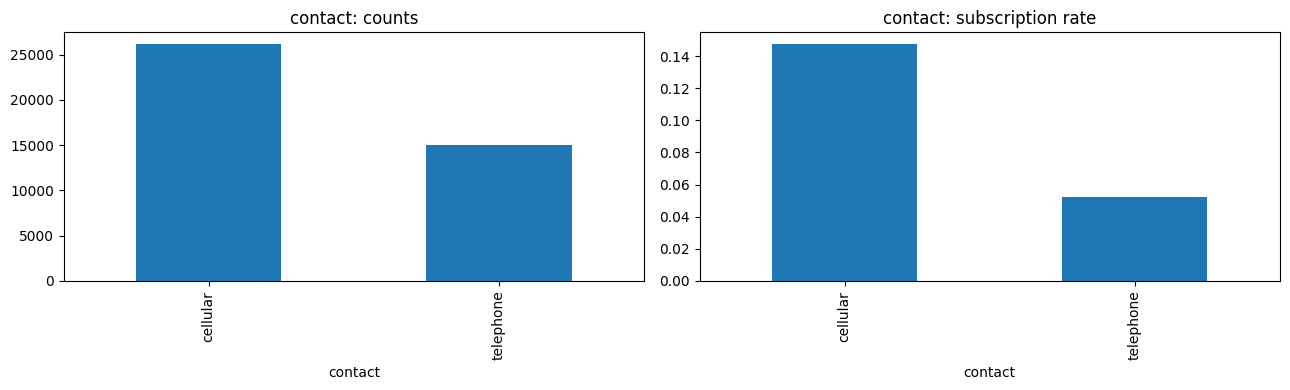

,count,subscribers,percent,subscription_rate
month,,,,
may,13769,886,33.429640,0.064347
jul,7174,649,17.417694,0.090466
aug,6178,655,14.999514,0.106021
jun,5318,559,12.911528,0.105115
nov,4101,416,9.956784,0.101439
apr,2632,539,6.390211,0.204787
oct,718,315,1.743226,0.438719
sep,570,256,1.383898,0.449123
mar,546,276,1.325629,0.505495


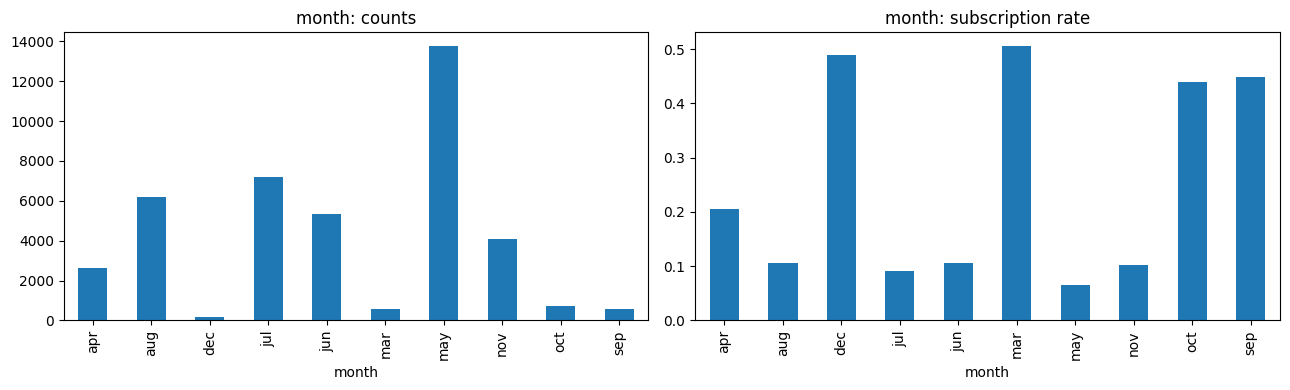

,count,subscribers,percent,subscription_rate
day_of_week,,,,
thu,8623,1045,20.935709,0.121188
mon,8514,847,20.671069,0.099483
wed,8134,949,19.748470,0.116671
tue,8090,953,19.641643,0.117800
fri,7827,846,19.003108,0.108087


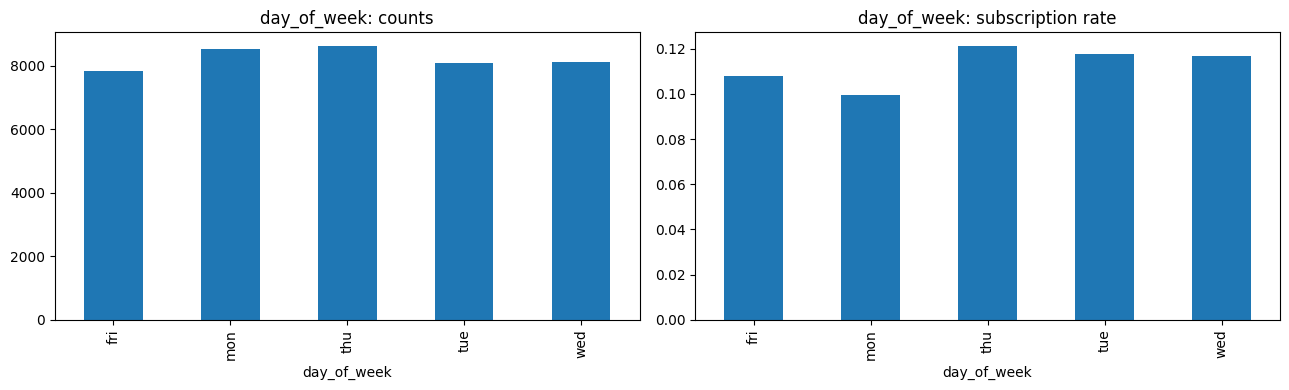

,count,subscribers,percent,subscription_rate
poutcome,,,,
nonexistent,35563,3141,86.343110,0.088322
failure,4252,605,10.323395,0.142286
success,1373,894,3.333495,0.651129


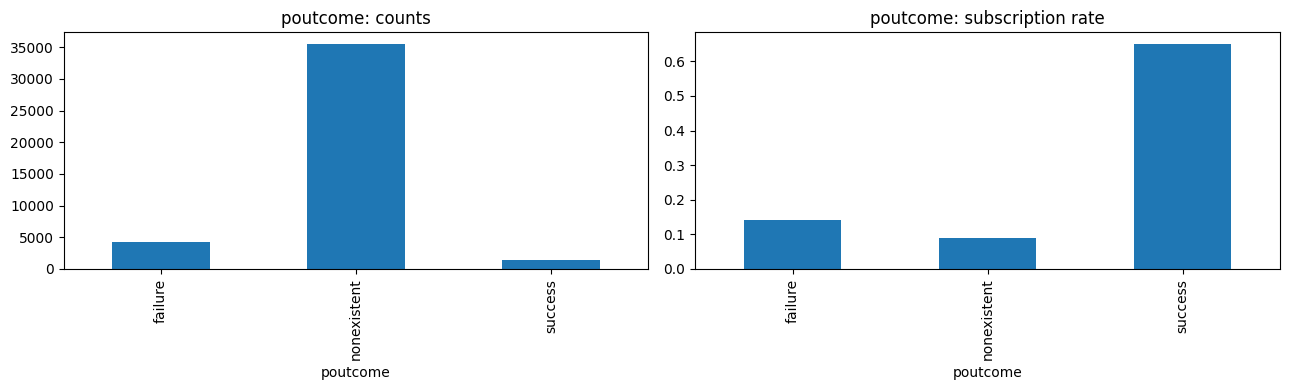

In [18]:
# Newly added: categorical coverage, counts and subscription rates
for col in ['marital', 'contact', 'month', 'day_of_week', 'poutcome']:
    table = raw_df.groupby(col, observed=True)['y'].agg(count='size', subscribers=lambda s: s.eq('yes').sum())
    table['percent'] = 100 * table['count'] / len(raw_df)
    table['subscription_rate'] = table['subscribers'] / table['count']
    display(table.sort_values('count', ascending=False))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    table['count'].plot.bar(ax=axes[0], title=f'{col}: counts')
    table['subscription_rate'].plot.bar(ax=axes[1], title=f'{col}: subscription rate')
    plt.tight_layout(); plt.show()


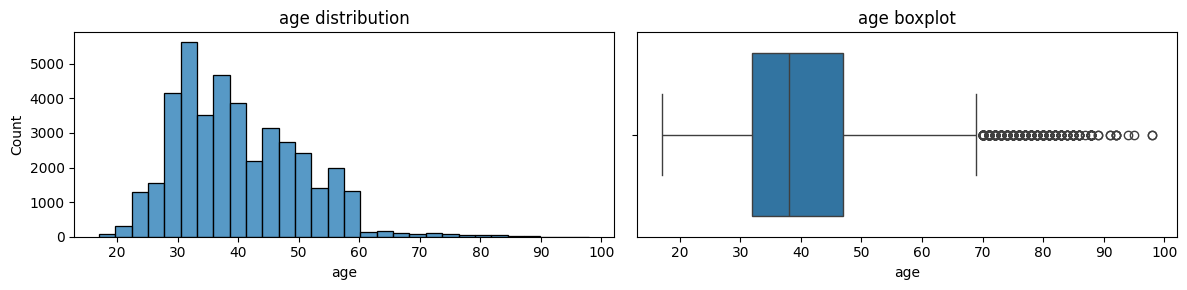

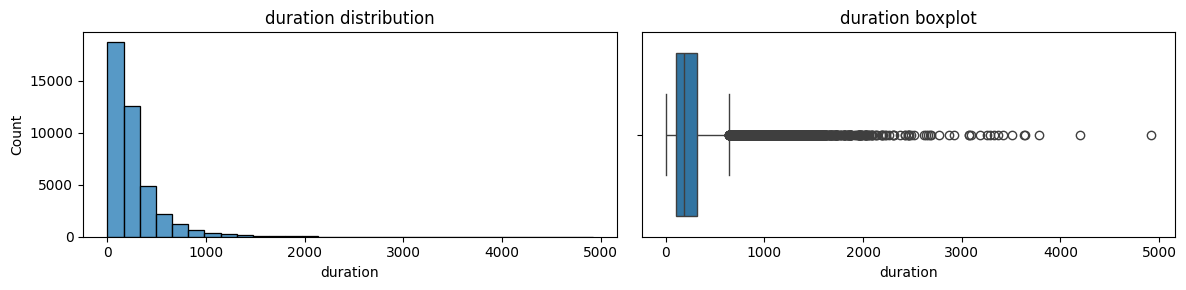

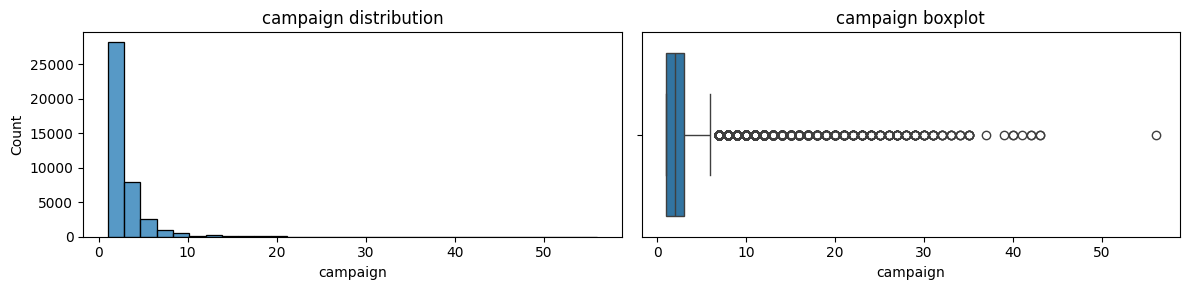

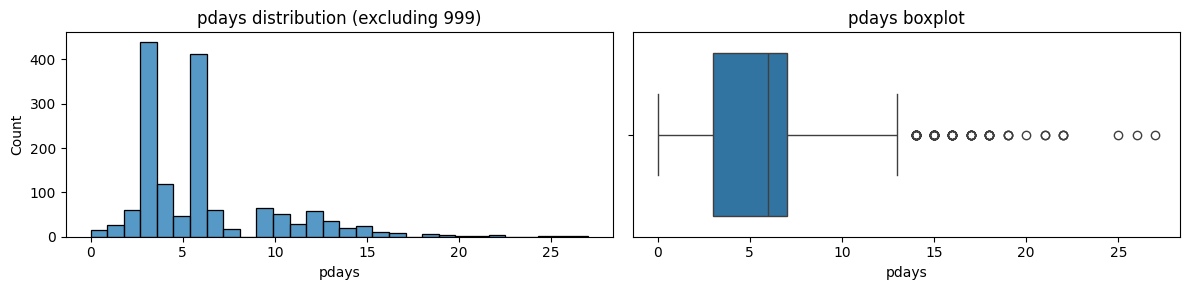

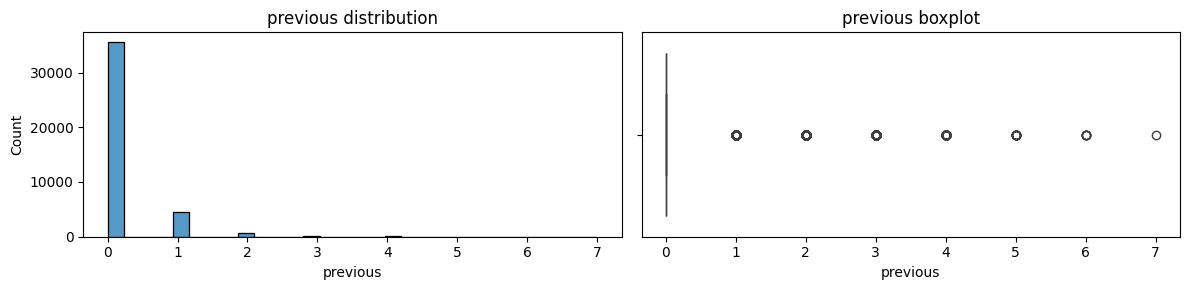

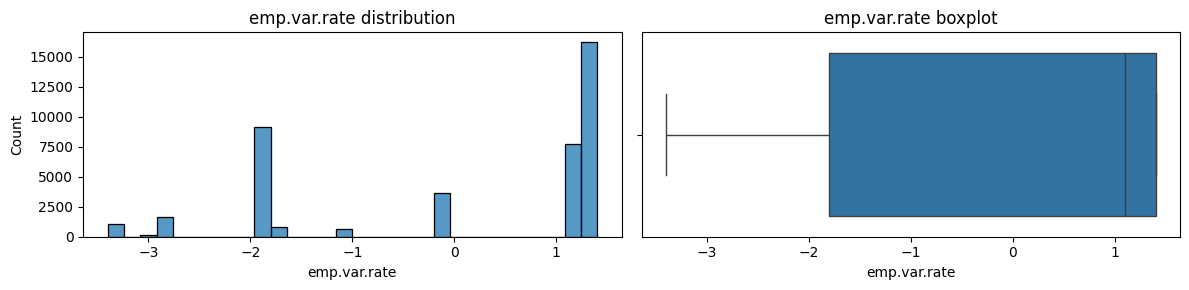

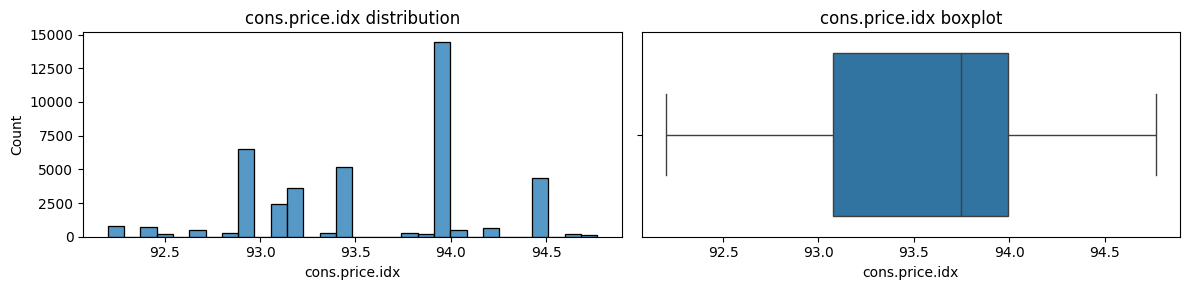

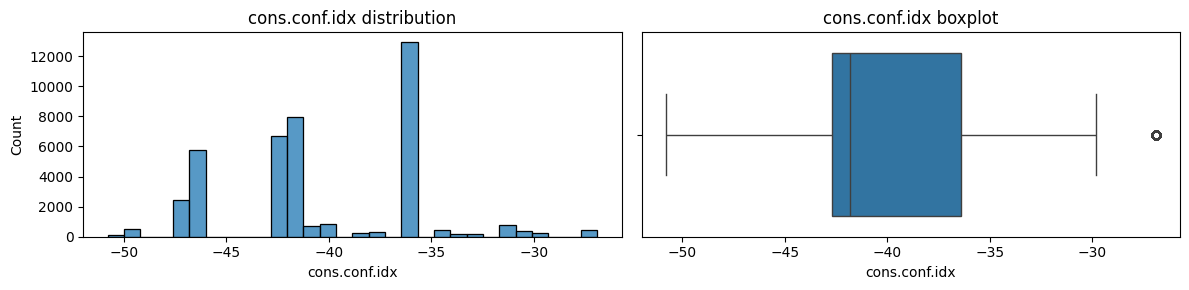

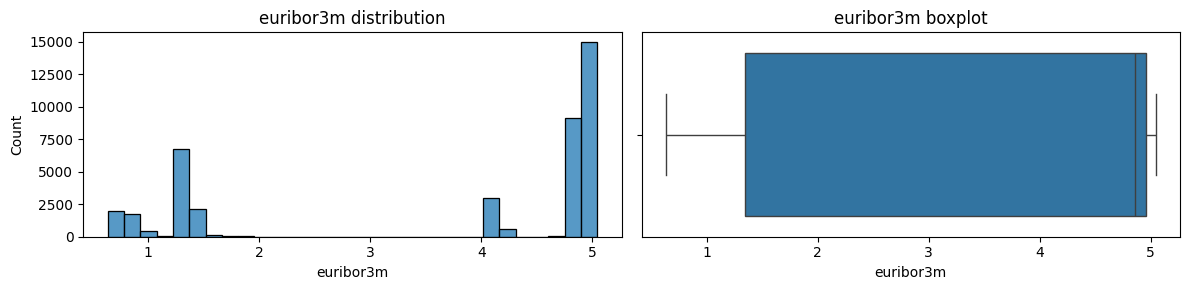

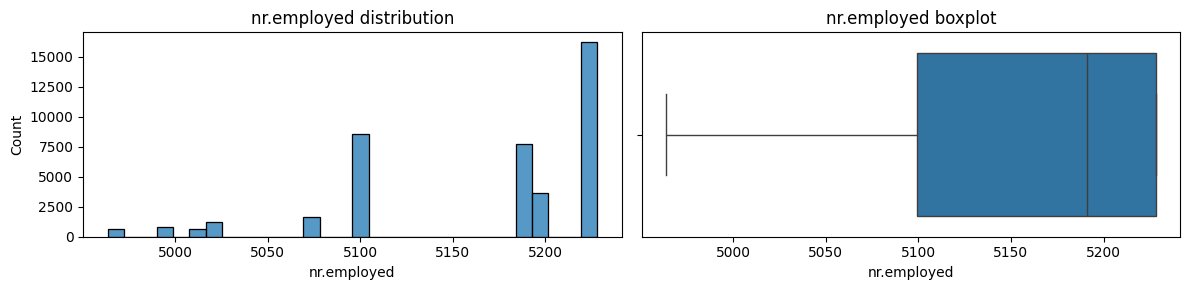

duration is descriptive only; do not use it for predictions before a call ends.


In [19]:
# Newly added: numerical distributions including descriptive-only duration
numeric = raw_df.select_dtypes(include=np.number).columns
for col in numeric:
    values = raw_df.loc[raw_df['pdays'].ne(999), col] if col == 'pdays' else raw_df[col]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    sns.histplot(values, bins=30, ax=axes[0])
    sns.boxplot(x=values, ax=axes[1])
    axes[0].set_title(f'{col} distribution' + (' (excluding 999)' if col == 'pdays' else ''))
    axes[1].set_title(f'{col} boxplot')
    plt.tight_layout(); plt.show()
print('duration is descriptive only; do not use it for predictions before a call ends.')


,count,subscribers,subscription_rate
campaign_group,,,
1,17642,2300,0.130371
2,10570,1211,0.114570
3,5341,574,0.107471
4–5,4250,369,0.086824
6–10,2516,159,0.063196
11+,869,27,0.031070


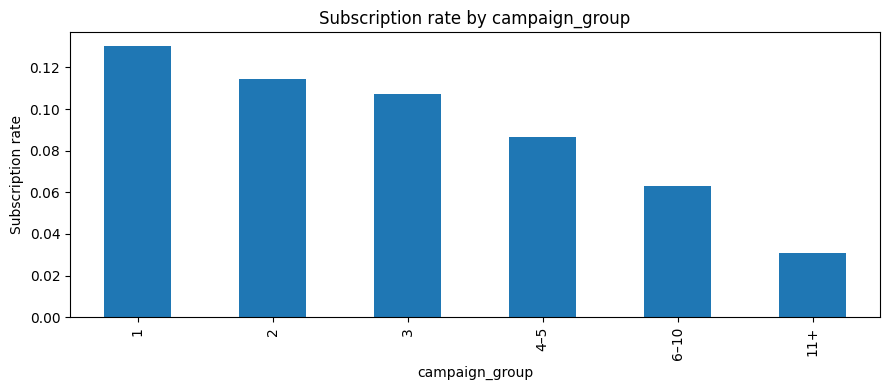

,count,subscribers,subscription_rate
previous,,,
0,35563,3141,0.088322
1,4561,967,0.212015
2,754,350,0.464191
3,216,128,0.592593
4,70,38,0.542857
5,18,13,0.722222
6,5,3,0.600000
7,1,0,0.000000


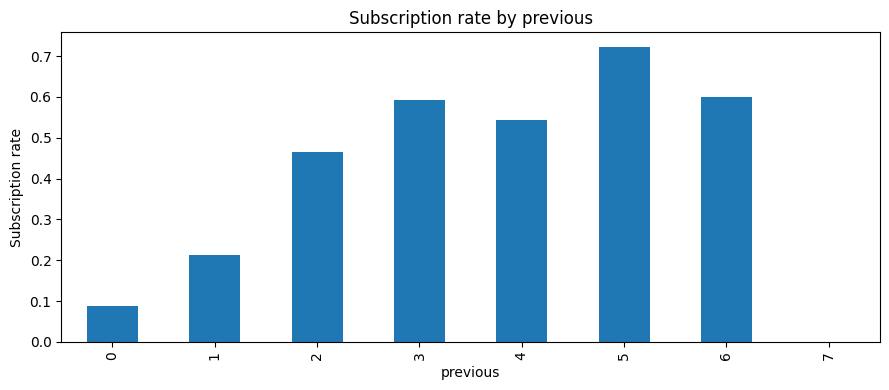

,count,subscribers,subscription_rate
previously_contacted,,,
False,39673,3673,0.092582
True,1515,967,0.638284


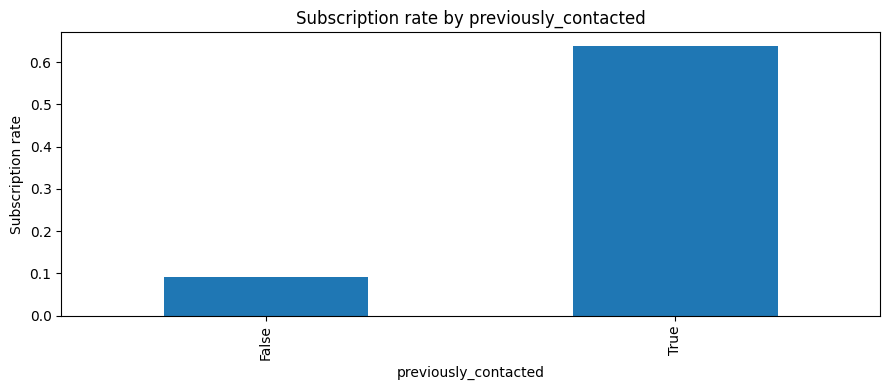

In [20]:
# Newly added: current contact frequency and previous campaign exposure
explore = raw_df.assign(subscribed=raw_df['y'].eq('yes').astype(int))
explore['campaign_group'] = pd.cut(explore['campaign'], [0, 1, 2, 3, 5, 10, np.inf], labels=['1', '2', '3', '4–5', '6–10', '11+'])
explore['previously_contacted'] = explore['pdays'].ne(999)
for col in ['campaign_group', 'previous', 'previously_contacted']:
    table = explore.groupby(col, observed=True)['subscribed'].agg(count='size', subscribers='sum', subscription_rate='mean')
    display(table)
    table['subscription_rate'].plot.bar(figsize=(9, 4), title=f'Subscription rate by {col}')
    plt.ylabel('Subscription rate'); plt.tight_layout(); plt.show()


age            duration             campaign            pdays  \
    median       mean   median        mean   median      mean median   
y                                                                      
no    38.0  39.911185    163.5  220.844807      2.0  2.633085  999.0   
yes   37.0  40.913147    449.0  553.191164      2.0  2.051724  999.0   

                previous           emp.var.rate           cons.price.idx  \
           mean   median      mean       median      mean         median   
y                                                                          
no   984.113878      0.0  0.132374          1.1  0.248875         93.918   
yes  792.035560      0.0  0.492672         -1.8 -1.233448         93.200   

               cons.conf.idx            euribor3m           nr.employed  \
          mean        median       mean    median      mean      median   
y                                                                         
no   93.603757         -41.8 -40.593097     4.857  3.811491      5195.8   
yes  93.354386         -40.4 -39.789784     1.266  2.123135      5099.1   

                  
            mean  
y                 
no   5176.166600  
yes  5095.115991

,count,median,mean
y,,,
no,548,6.0,6.193431
yes,967,6.0,5.913133


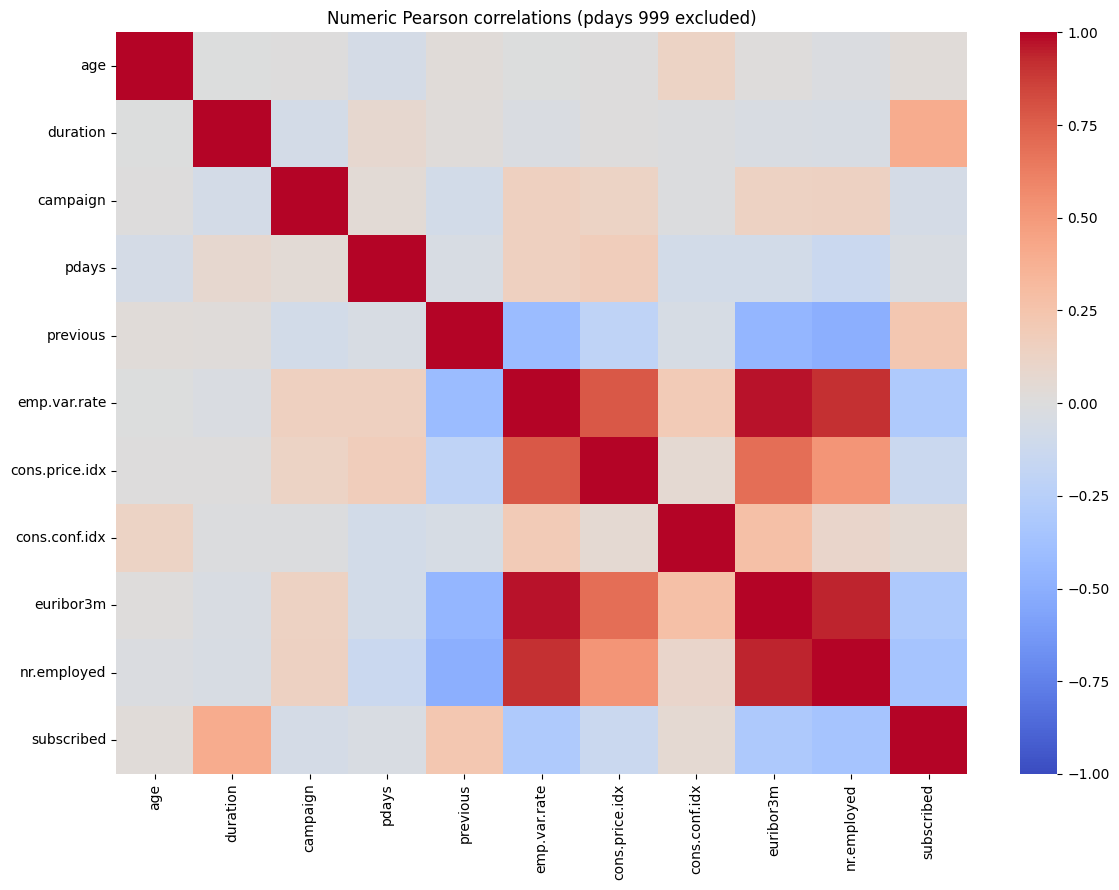

The full group summary retains raw pdays for transparency; use the valid-interval table for interpretation.
Correlations are descriptive. Economic variables may be correlated; this does not establish causation.


In [21]:
# Newly added: numeric summaries by outcome and correlations
numeric_eda = explore.select_dtypes(include=np.number).copy()
numeric_eda.loc[explore['pdays'].eq(999), 'pdays'] = np.nan
# Sentinel is excluded here; valid pdays describe only previously contacted records.
display(explore.groupby('y')[list(numeric)].agg(['median', 'mean']))
display(explore.loc[explore['pdays'].ne(999)].groupby('y')['pdays'].agg(['count', 'median', 'mean']))
corr = numeric_eda.corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Numeric Pearson correlations (pdays 999 excluded)')
plt.tight_layout(); plt.show()
print('The full group summary retains raw pdays for transparency; use the valid-interval table for interpretation.')
print('Correlations are descriptive. Economic variables may be correlated; this does not establish causation.')


## Model baseline

A simple decision tree provides a quick classification baseline and a useful view of where the model struggles.


Test accuracy: 0.8456

Recall by subscription outcome:
 no     0.910534
yes    0.334052
Name: Recall, dtype: float64

Classification report:

              precision    recall  f1-score   support

          no       0.92      0.91      0.91      7310
         yes       0.32      0.33      0.33       928

    accuracy                           0.85      8238
   macro avg       0.62      0.62      0.62      8238
weighted avg       0.85      0.85      0.85      8238



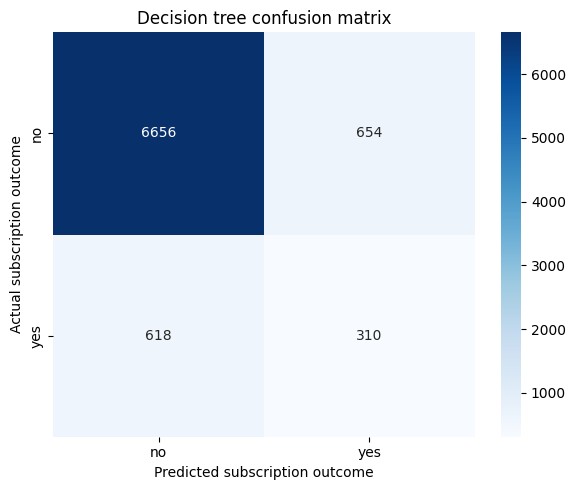

In [22]:
X = bank.drop(columns=["y", "success", "poutcome"], errors="ignore").copy()
y = bank["y"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

categorical_cols = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
numerical_cols = X.select_dtypes(include=[np.number]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("numerical", "passthrough", numerical_cols),
    ]
)

clf = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("tree", DecisionTreeClassifier(random_state=8675309, class_weight="balanced")),
    ]
)

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")

recall_by_class = pd.Series(
    recall_score(y_test, y_pred, labels=["no", "yes"], average=None, zero_division=0),
    index=["no", "yes"],
    name="Recall",
)
print("\nRecall by subscription outcome:\n", recall_by_class)
print("\nClassification report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=["no", "yes"])
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["no", "yes"],
    yticklabels=["no", "yes"],
)
plt.xlabel("Predicted subscription outcome")
plt.ylabel("Actual subscription outcome")
plt.title("Decision tree confusion matrix")
plt.tight_layout()
plt.show()


In [23]:
# Newly added: majority-class comparator on the same held-out split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score
majority = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
majority_pred = majority.predict(X_test)
comparison = pd.DataFrame({
    'model': ['Majority class', 'Original balanced decision tree'],
    'accuracy': [accuracy_score(y_test, majority_pred), accuracy_score(y_test, y_pred)],
    'balanced_accuracy': [balanced_accuracy_score(y_test, majority_pred), balanced_accuracy_score(y_test, y_pred)],
    'yes_recall': [recall_score(y_test, majority_pred, pos_label='yes', zero_division=0), recall_score(y_test, y_pred, pos_label='yes', zero_division=0)]
})
display(comparison)


,model,accuracy,balanced_accuracy,yes_recall
0,Majority class,0.887351,0.500000,0.000000
1,Original balanced decision tree,0.845594,0.622293,0.334052
